# PathSnap — full team project on Kaggle

Enable **Internet** in Kaggle notebook settings, select a CPU session, and choose **Run All**. This notebook clones the latest inspected main revision, rebuilds the data, trains all five classifiers, runs all classifier/tree/decoder searches, generates plots, benchmarks and profiles routing, runs repository checks, and displays the API map and browser UI source. Long searches may exceed one Kaggle session. Outputs and individual command logs are saved under `/kaggle/working`; download them from the Output panel. No code is executed by merely downloading this notebook.

Coverage: preprocessing notebook; candidate and label generators; Logistic Regression, KNN, Random Forest, XGBoost and MLP; classifier and tree tuning; scoring CLI for every trained artifact; all visualization scripts; Viterbi tuning; default/selected/cached route benchmarks; trip profiling and viewer; API and Folium map; UI files; repository tests. Documentation, GitHub workflow configuration and two-laptop networking are included as evidence/files, but require their respective environments for demonstration.


In [1]:
from pathlib import Path
import subprocess, sys, os, json, time, shutil
from IPython.display import display, HTML, FileLink
REPO = Path('/kaggle/working/ML-HACKATHON')
REVISION = '9fc9298037430e3a11f95ae24b7639306a42a74f'
if not REPO.exists():
    subprocess.run(['git','clone','https://github.com/vasishtcoffee/ML-HACKATHON.git',str(REPO)],check=True)
subprocess.run(['git','fetch','origin'],cwd=REPO,check=True)
subprocess.run(['git','checkout',REVISION],cwd=REPO,check=True)
os.chdir(REPO)
print('Reproducing main revision:', REVISION)


Cloning into '/kaggle/working/ML-HACKATHON'...
Updating files: 100% (124/124), done.


Reproducing main revision: 9fc9298037430e3a11f95ae24b7639306a42a74f


Note: switching to '9fc9298037430e3a11f95ae24b7639306a42a74f'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 9fc9298 Merge pull request #14 from vasishtcoffee/pathsnap/viterbi-tuning-speed


In [2]:
# Keep pinned project packages separate from Kaggle's running notebook kernel.
BASE_PYTHON=sys.executable
ENV=Path('/kaggle/working/pathsnap_env')
subprocess.run([BASE_PYTHON,'-m','pip','install','virtualenv'],check=True)
subprocess.run([BASE_PYTHON,'-m','virtualenv',str(ENV)],check=True)
PROJECT_PYTHON=str(ENV/'bin/python')
requirements=sorted(str(p) for p in Path('requirements').glob('requirements-*.txt'))
subprocess.run([PROJECT_PYTHON,'-m','pip','install',*sum((['-r',p] for p in requirements),[]),'nbconvert','requests','httpx'],check=True)
subprocess.run([PROJECT_PYTHON,'-m','ipykernel','install','--user','--name','pathsnap-project'],check=True)
# Script, training, API and subprocess notebook execution all use the isolated interpreter.
sys.executable=PROJECT_PYTHON
subprocess.run([PROJECT_PYTHON,'-c','import numpy,pandas,scipy,sklearn,xgboost,optuna,folium,pyarrow,fastapi,uvicorn,joblib,matplotlib; print("Project dependency imports OK")'],check=True)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 28.9 MB/s  0:00:00

created virtual environment CPython3.13.18.final.0-64-x86_64 in 469ms
  creator CPython3Posix(dest=/kaggle/working/pathsnap_env, clear=False, no_vcs_ignore=False, venv_redirect=None, global=False)
  seeder FromAppData(download=False, pip=bundle, via=copy, app_data_dir=/root/.cache/virtualenv)
    added seed packages: pip==26.3
  activators BashActivator,CShellActivator,FishActivator,NushellActivator,PowerShellActivator,PythonActivator,XonshActivator


Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 54.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 104.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 130.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 89.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 71.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 70.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 78.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 61.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 69.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 649.8/649.8 kB 11.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 61.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 27.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 73.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━

Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


Installed kernelspec pathsnap-project in /root/.local/share/jupyter/kernels/pathsnap-project


Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


Project dependency imports OK


CompletedProcess(args=['/kaggle/working/pathsnap_env/bin/python', '-c', 'import numpy,pandas,scipy,sklearn,xgboost,optuna,folium,pyarrow,fastapi,uvicorn,joblib,matplotlib; print("Project dependency imports OK")'], returncode=0)

In [3]:
import pandas as pd
import numpy as np

LOGS=Path('/kaggle/working/pathsnap_logs'); LOGS.mkdir(exist_ok=True)
completed=[]
def command(label, args):
    print('START', label, flush=True)
    with (LOGS/(label+'.log')).open('w') as log:
        proc=subprocess.Popen(args,cwd=REPO,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
        for line in proc.stdout:
            print(line,end='',flush=True); log.write(line); log.flush()
        status=proc.wait()
    if status: raise RuntimeError(f'{label} failed ({status}); see {LOGS/(label+".log")}')
    completed.append(label)
    (LOGS/'completed.json').write_text(json.dumps(completed,indent=2))
def run(label, script, *args): command(label,[sys.executable,script,*args])


## Preprocessing


In [4]:
command('preprocessing', [sys.executable, *['-m', 'jupyter', 'nbconvert', '--execute', '--to', 'notebook', '--ExecutePreprocessor.timeout=-1', '--ExecutePreprocessor.kernel_name=pathsnap-project', 'notebooks/gps_preprocessing.ipynb', '--output', 'gps_preprocessing_executed.ipynb']])


START preprocessing
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
/usr/local/lib/python3.13/dist-packages/mistune.py:435: SyntaxWarning: invalid escape sequence '\|'
  cells[i][c] = re.sub('\\\\\|', '|', cell)
/usr/local/lib/python3.13/dist-packages/nbconvert/filters/filter_links.py:36: SyntaxWarning: invalid escape sequence '\_'
  text = re.sub(r'_', '\_', text) # Escape underscores in display text
[NbConvertApp] Converting notebook notebooks/gps_preprocessing.ipynb to notebook
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.
[NbConvertApp] Writing 2100314 bytes to notebooks/gps_preprocessing_execute

## Candidates


In [5]:
command('candidates', [sys.executable, *['scripts/generate_candidates.py']])


START candidates
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
              observations  observations_without_candidates  candidate_rows
split                                                                      
student_test         19160                                0          209582
train               208417                            18229         1869567


## Labels


In [6]:
command('labels', [sys.executable, *['scripts/generate_reference_labels.py']])


START labels
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
              observations  aligned  ambiguous  unmatched  zero_candidates  aligned_arc_missing  aligned_with_other_candidates  usable_for_training
split                                                                                                                                              
student_test         19160    16317       2822         21                0                    6                              6                    0
train               208417   163219      23320      21878            18229                 1262                            557               161957


## Baselines


In [7]:
command('baselines', [sys.executable, *['scripts/train_baselines.py', '--models', 'logistic_regression', 'knn']])


START baselines
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
logistic_regression fold 1: macro F1=0.7302, top-1=0.5857
logistic_regression fold 2: macro F1=0.7252, top-1=0.5801
logistic_regression fold 3: macro F1=0.6996, top-1=0.5082
logistic_regression fold 4: macro F1=0.7434, top-1=0.5896
logistic_regression fold 5: macro F1=0.7095, top-1=0.5507
logistic_regression fit 1,469,580 candidates from 80 trips
logistic_regression train_fit: macro F1=0.7207, top-1=0.5596
logistic_regression student_test: macro F1=0.7146, top-1=0.5444
knn fold 1: macro F1=0.7339, top-1=0.5510
knn fold 2: macro F1=0.7497, top-1=0.5686
knn fold 3: macro F1=0.7360, top-1=0.5255
knn fold 4: macro F1=0.7485, top-1=0.5870
knn fold 5: macro F1=0.7377, top-1=0.5431
knn fit 1,469,580 candidates from 80 trips
knn train_fit: macro F1=0.7820, top-1=0.6257
knn student_test: macro F1=0.7435, top-1=0.5465


## Random Forest


In [8]:
command('random_forest', [sys.executable, *['scripts/train_baselines.py', '--models', 'random_forest', '--output', 'experiments/random_forest']])


START random_forest
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
random_forest fold 1: macro F1=0.7634, top-1=0.5852
random_forest fold 2: macro F1=0.7746, top-1=0.5827
random_forest fold 3: macro F1=0.7147, top-1=0.5141
random_forest fold 4: macro F1=0.7612, top-1=0.5974
random_forest fold 5: macro F1=0.7377, top-1=0.5474
random_forest fit 1,469,580 candidates from 80 trips
random_forest train_fit: macro F1=0.7760, top-1=0.6103
random_forest student_test: macro F1=0.7450, top-1=0.5470


## Xgboost


In [9]:
command('xgboost', [sys.executable, *['scripts/train_baselines.py', '--models', 'xgboost', '--output', 'experiments/xgboost']])


START xgboost
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
xgboost fold 1: macro F1=0.7648, top-1=0.5878
xgboost fold 2: macro F1=0.7760, top-1=0.5809
xgboost fold 3: macro F1=0.7139, top-1=0.5111
xgboost fold 4: macro F1=0.7647, top-1=0.5905
xgboost fold 5: macro F1=0.7466, top-1=0.5520
xgboost fit 1,469,580 candidates from 80 trips
xgboost train_fit: macro F1=0.7631, top-1=0.5723
xgboost student_test: macro F1=0.7488, top-1=0.5467


## Mlp


In [10]:
command('mlp', [sys.executable, *['scripts/train_mlp.py']])


START mlp
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
fold 1 epoch 1/10: objective=0.19773
fold 1 epoch 2/10: objective=0.18057
fold 1 epoch 3/10: objective=0.17822
fold 1 epoch 4/10: objective=0.17698
fold 1 epoch 5/10: objective=0.17623
fold 1 epoch 6/10: objective=0.17568
fold 1 epoch 7/10: objective=0.17529
fold 1 epoch 8/10: objective=0.17503
fold 1 epoch 9/10: objective=0.17484
fold 1 epoch 10/10: objective=0.17469
fold 1: macro F1=0.7698, top-1=0.5840
fold 2 epoch 1/10: objective=0.19168
fold 2 epoch 2/10: objective=0.17340
fold 2 epoch 3/10: objective=0.17135
fold 2 epoch 4/10: objective=0.17018
fold 2 epoch 5/10: objective=0.16964
fold 2 epoch 6/10: objective=0.16930
fold 2 epoch 7/10: objective=0.16904
fold 2 epoch 8/10: objective=0.16884
fold 2 epoch 9/10: objective=0.16867
fold 2 epoch 10/10: objective=0.16852
fold 2: macro F1=0.7839, top-1=0.5807
fold 3 epoch 1/10: objective=0.18335
fold 3 epoch 2/10: objective=0.16

## Classifier Tuning


In [11]:
command('classifier_tuning', [sys.executable, *['scripts/tune_classifiers.py', '--trials', '8']])


START classifier_tuning
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
Optimizing logistic_regression
[I 2026-11-18 08:09:16,174] A new study created in memory with name: no-name-40102f6b-4c74-4fff-8ccd-d5ce5c18ba4a
[I 2026-11-18 08:09:22,076] Trial 0 finished with value: 0.5610687368645241 and parameters: {'C': 1.0, 'positive_weight': 1.0}. Best is trial 0 with value: 0.5610687368645241.
[I 2026-11-18 08:09:28,054] Trial 1 finished with value: 0.5609683132448527 and parameters: {'C': 0.0745934328572655, 'positive_weight': 1.0}. Best is trial 0 with value: 0.5610687368645241.
[I 2026-11-18 08:09:33,968] Trial 2 finished with value: 0.5600392497149228 and parameters: {'C': 0.0060252157362038605, 'positive_weight': 2.0}. Best is trial 0 with value: 0.5610687368645241.
[I 2026-11-18 08:09:40,065] Trial 3 finished with value: 0.5610816515305529 and parameters: {'C': 68.535705111043, 'positive_weight': 1.0}. Best is trial 3 with value: 

## Forest Tuning


In [12]:
command('forest_tuning', [sys.executable, *['scripts/tune_tree_models.py', '--model', 'random_forest', '--trials', '6']])


START forest_tuning
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
[I 2026-11-18 08:17:26,836] A new study created in memory with name: no-name-f1ba64cf-b1f7-441c-8ba4-23a9a4c901f4
[I 2026-11-18 08:22:43,454] Trial 0 finished with value: 0.5614108547658359 and parameters: {'max_depth': 16, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': None}. Best is trial 0 with value: 0.5614108547658359.
[I 2026-11-18 08:27:11,464] Trial 1 finished with value: 0.5619436376198349 and parameters: {'max_depth': 12, 'min_samples_leaf': 70, 'max_features': 'sqrt', 'class_weight': None}. Best is trial 1 with value: 0.5619436376198349.
[I 2026-11-18 08:33:09,913] Trial 2 finished with value: 0.5637204274981437 and parameters: {'max_depth': 8, 'min_samples_leaf': 55, 'max_features': 1.0, 'class_weight': 'balanced'}. Best is trial 2 with value: 0.5637204274981437.
[I 2026-11-18 08:39:00,201] Trial 3 finished with value: 0.5635762371348337

## Xgboost Tuning


In [13]:
command('xgboost_tuning', [sys.executable, *['scripts/tune_tree_models.py', '--model', 'xgboost', '--trials', '6']])


START xgboost_tuning
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
[I 2026-11-18 09:25:06,591] A new study created in memory with name: no-name-6ac59dc2-1e33-4717-9134-886d94865dd0
[I 2026-11-18 09:25:37,414] Trial 0 finished with value: 0.5618948064740245 and parameters: {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.05, 'min_child_weight': 10, 'reg_lambda': 1.0}. Best is trial 0 with value: 0.5618948064740245.
[I 2026-11-18 09:26:10,517] Trial 1 finished with value: 0.5591119949789155 and parameters: {'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.10790061933340454, 'min_child_weight': 30.049873591901573, 'reg_lambda': 2.05133826308745}. Best is trial 0 with value: 0.5618948064740245.
[I 2026-11-18 09:26:21,879] Trial 2 finished with value: 0.5635847815217663 and parameters: {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.146962368105409, 'min_child_weight': 30.271829277346235, 'reg_lambda': 26.070247

## Tree Comparison


In [14]:
command('tree_comparison', [sys.executable, *['scripts/compare_tree_models.py']])


START tree_comparison
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
                run  cv_top1_mean  cv_top1_std  student_top1  student_macro_f1  student_log_loss  student_continuity  inference_seconds
      random_forest      0.565347     0.034148      0.547037          0.744988          0.161843            0.823773           0.858344
            xgboost      0.564432     0.033523      0.546730          0.748780          0.160645            0.820685           0.466068
      xgboost_tuned      0.565219     0.034052      0.547588          0.750390          0.160241            0.821156           0.089369
random_forest_tuned      0.566002     0.034098      0.547221          0.781752          0.263845            0.823040           0.969284


## Baseline Figures


In [15]:
command('baseline_figures', [sys.executable, *['scripts/visualize_baselines.py']])


START baseline_figures
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


## Mlp Figures


In [16]:
command('mlp_figures', [sys.executable, *['scripts/visualize_mlp.py']])


START mlp_figures
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


## Classifier Tuning Figures


In [17]:
command('classifier_tuning_figures', [sys.executable, *['scripts/visualize_classifier_tuning.py']])


START classifier_tuning_figures
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


## Viterbi Tuning


In [18]:
command('viterbi_tuning', [sys.executable, *['scripts/tune_viterbi.py']])


START viterbi_tuning
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
Training calibration: ['00000014', '00000027', '00000048', '00000058', '00000060', '00000095']
Training holdout: ['00000010', '00000011', '00000057', '00000089']
beta=15 gap=3: accuracy=68.3529%, continuity=94.4860%, breaks=79, decode=19.7s
beta=15 gap=5: accuracy=68.1329%, continuity=94.5794%, breaks=65, decode=21.0s
beta=15 gap=10: accuracy=68.2796%, continuity=94.5981%, breaks=48, decode=22.2s
beta=30 gap=3: accuracy=69.9902%, continuity=94.7103%, breaks=79, decode=21.2s
beta=30 gap=5: accuracy=69.7703%, continuity=94.7850%, breaks=65, decode=24.0s
beta=30 gap=10: accuracy=69.7947%, continuity=94.8037%, breaks=48, decode=22.7s
beta=60 gap=3: accuracy=72.3851%, continuity=94.6355%, breaks=79, decode=20.5s
beta=60 gap=5: accuracy=72.3118%, continuity=94.6916%, breaks=65, decode=21.7s
beta=60 gap=10: accuracy=72.4829%, continuity=94.7290%, breaks=48, decode=21.5s
C

## Routing Profile


In [19]:
command('routing_profile', [sys.executable, *['scripts/profile_trip.py']])


START routing_profile
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
{"trip_id": "00000009", "model": "knn", "cache_size": 0, "gps_observations": 1049, "candidate_rows": 20779, "route_segments": 2, "route_breaks": 1, "decode_seconds": 11.470297076999486, "road_routing_seconds": 10.666699095353579, "dijkstra_seconds": 9.280491889253426, "dijkstra_searches": 584505, "shortest_cache_hits": 0, "map_render_seconds": 1.40370172799976, "map_html_bytes": 1610636}
{"trip_id": "00000009", "model": "knn", "cache_size": 20000, "gps_observations": 1049, "candidate_rows": 20779, "route_segments": 2, "route_breaks": 1, "decode_seconds": 3.3664013819998218, "road_routing_seconds": 2.6309140264283997, "dijkstra_seconds": 1.1125183830354217, "dijkstra_searches": 52976, "shortest_cache_hits": 531529, "map_render_seconds": 1.5317718789992796, "map_html_bytes": 1610636}
COMPARISON {"status": "exact route and GPS arc predictions verified identical", "sa

## Route Default


In [20]:
command('route_default', [sys.executable, *['scripts/benchmark_trained_decoding.py', '--output', 'experiments/route_comparison_default']])


START route_default
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'

Scorer: logistic_regression
logistic_regression 00000000 | Top-1 53.51%, Viterbi 95.10%, direct continuity 90.33% -> 98.44%, decode 0.90s
logistic_regression 00000007 | Top-1 45.44%, Viterbi 86.59%, direct continuity 92.09% -> 99.56%, decode 0.15s
logistic_regression 00000009 | Top-1 55.67%, Viterbi 82.72%, direct continuity 66.60% -> 89.41%, decode 11.45s
logistic_regression 00000040 | Top-1 53.78%, Viterbi 86.82%, direct continuity 89.58% -> 98.13%, decode 0.80s
logistic_regression 00000052 | Top-1 80.79%, Viterbi 99.51%, direct continuity 77.01% -> 95.79%, decode 0.11s
logistic_regression 00000056 | Top-1 70.36%, Viterbi 88.32%, direct continuity 76.27% -> 95.53%, decode 7.64s
logistic_regression 00000065 | Top-1 74.96%, Viterbi 75.89%, direct continuity 79.40% -> 95.54%, decode 1.46s
logistic_regression 00000076 | Top-1 46.04%, Viterbi 80.89%, direct continuity

## Trip List


In [21]:
command('trip_list', [sys.executable, *['scripts/view_trip.py', '--list-trips']])


START trip_list
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
trip_id
00000001     1315
00000002     7243
00000003      821
00000004     1064
00000005     1045
00000006     1450
00000008     3093
00000010     2711
00000011     2828
00000012     1608
00000013     2580
00000014      448
00000016     1305
00000018      379
00000019     2354
00000020     2353
00000021    15783
00000022      474
00000024      801
00000025     1179
00000026      361
00000027      694
00000028     3565
00000029      733
00000031     4245
00000032     2464
00000033     5844
00000034     3614
00000035     1643
00000036     1368
00000037      677
00000038     1287
00000039      363
00000041     1019
00000042     7739
00000043     2322
00000044      546
00000045      640
00000046     1401
00000047     1272
00000048     1240
00000050      518
00000051      984
00000053     1304
00000054    19313
00000055     2472
00000057     1645
00000058      599
00000060  

## Trip Viewer


In [22]:
command('trip_viewer', [sys.executable, *['scripts/view_trip.py', '--split', 'student_test', '--trip-id', '00000052']])


START trip_viewer
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
{
  "split": "student_test",
  "trip_id": "00000052",
  "gps_observations": 262,
  "road_nodes": 1770,
  "road_arcs": 3577,
  "displayed_road_arcs": 1435,
  "gaps_over_5s": 0,
  "duration_seconds": 265.0
}
Map: /kaggle/working/ML-HACKATHON/data/viewer/student_test_00000052.html


## Repository Checks


In [23]:
command('repository_checks', [sys.executable, *['-m', 'unittest', 'discover', '-s', 'tests', '-v']])


START repository_checks
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
/kaggle/working/pathsnap_env/lib/python3.13/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
test_invalid_trip_rejected (test_api_smoke.FastAPIDemoTests.test_invalid_trip_rejected) ... ok
test_knn_prediction_and_separate_timing (test_api_smoke.FastAPIDemoTests.test_knn_prediction_and_separate_timing) ... ok
test_models_and_ten_student_trip_ids (test_api_smoke.FastAPIDemoTests.test_models_and_ten_student_trip_ids) ... ok
test_missed_reference_counts_against_both (test_evaluation.EvaluationTests.test_missed_reference_counts_against_both) ... ok
test_tied_probability_prefers_candidate_rank_over_arc_id (test_evaluation.EvaluationTests.test_tied_probability_prefers_candidate_rank_over_arc_id) ... ok


In [24]:
# Locate training-selected parameters, then benchmark selected settings with and without cache.
chosen=list((REPO/'experiments').rglob('chosen.json'))
if len(chosen)!=1: raise RuntimeError(f'Expected one Viterbi chosen.json, found {chosen}')
for cache in (0,20000):
    run(f'route_selected_cache_{cache}','scripts/benchmark_trained_decoding.py','--params-file',str(chosen[0]),'--cache-size',str(cache),'--output',f'experiments/route_selected_cache_{cache}')
# Exercise the standalone scoring interface on every freshly trained model artifact.
for model in sorted((REPO/'experiments').rglob('*.joblib')):
    relative=model.relative_to(REPO/'experiments')
    output=REPO/'data/rescored'/relative.with_suffix('.parquet')
    run('score_'+str(relative).replace('/','_'),'scripts/score_baseline.py',str(model),'data/processed/candidates_student_test.parquet',str(output))


START route_selected_cache_0
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'

Scorer: logistic_regression
logistic_regression 00000000 | Top-1 53.51%, Viterbi 94.72%, direct continuity 90.33% -> 97.64%, decode 0.94s
logistic_regression 00000007 | Top-1 45.44%, Viterbi 86.52%, direct continuity 92.09% -> 99.19%, decode 0.15s
logistic_regression 00000009 | Top-1 55.67%, Viterbi 80.45%, direct continuity 66.60% -> 83.11%, decode 11.54s
logistic_regression 00000040 | Top-1 53.78%, Viterbi 86.49%, direct continuity 89.58% -> 97.03%, decode 0.85s
logistic_regression 00000052 | Top-1 80.79%, Viterbi 99.51%, direct continuity 77.01% -> 95.40%, decode 0.11s
logistic_regression 00000056 | Top-1 70.36%, Viterbi 88.29%, direct continuity 76.27% -> 94.14%, decode 7.84s
logistic_regression 00000065 | Top-1 74.96%, Viterbi 76.82%, direct continuity 79.40% -> 94.36%, decode 1.47s
logistic_regression 00000076 | Top-1 46.04%, Viterbi 80.06%, direct c

experiments/baselines/metrics.csv


,model,phase,fold,trips_evaluated,scored_candidates,inference_seconds,aligned_observations,ambiguous_observations,unmatched_observations,candidate_misses,...,candidate_log_loss,top1_accuracy,continuity,continuity_transitions,tn,fp,fn,tp,fit_seconds,fit_candidates
0,logistic_regression,cv,1.0,15,319903,0.027638,21420,3179,17148,157,...,0.156104,0.585714,0.802964,25036,216372,6123,12112,9151,2.181261,1225822
1,logistic_regression,cv,2.0,16,387043,0.026884,37157,4180,402,497,...,0.194189,0.580133,0.850254,40809,280771,10537,20792,15868,2.145789,1141612
2,logistic_regression,cv,3.0,16,319391,0.025884,37616,4120,1,32,...,0.233151,0.508215,0.842639,41497,208085,15088,20996,16588,1.859678,1208823
3,logistic_regression,cv,4.0,16,417908,0.040606,32168,6079,3170,480,...,0.198142,0.589623,0.795194,40702,262998,9873,16523,15165,2.239588,1165021
4,logistic_regression,cv,5.0,17,425322,0.036355,34858,5762,1157,96,...,0.176079,0.550720,0.820408,40748,286398,11378,20516,14246,2.162909,1137042
5,logistic_regression,train_fit,NaN,80,1869567,0.139374,163219,23320,21878,1262,...,0.190982,0.559610,0.823986,188792,1254748,52875,91186,70771,2.627256,1469580
6,logistic_regression,student_test,NaN,10,209582,0.018213,16317,2822,21,6,...,0.172522,0.544402,0.820946,19106,137183,5408,9442,6869,2.627256,1469580
7,knn,cv,1.0,15,319903,15.272428,21420,3179,17148,157,...,0.171110,0.550980,0.787626,25036,213914,8581,11005,10258,2.304193,1225822
8,knn,cv,2.0,16,387043,18.618486,37157,4180,402,497,...,0.198614,0.568587,0.841604,40809,275743,15565,16624,20036,2.166789,1141612
9,knn,cv,3.0,16,319391,14.904044,37616,4120,1,32,...,0.243867,0.525548,0.839964,41497,203819,19354,15896,21688,2.205799,1208823


experiments/classifier_tuning/knn/metrics.csv


,model,phase,fold,trips_evaluated,scored_candidates,inference_seconds,aligned_observations,ambiguous_observations,unmatched_observations,candidate_misses,...,candidate_log_loss,top1_accuracy,continuity,continuity_transitions,tn,fp,fn,tp,fit_candidates,fit_seconds
0,knn,student_test,NaN,10,209582,13.748475,16317,2822,21,6,...,0.179043,0.546976,0.82058,19106,135216,7375,7471,8840,1469580,2.665609


experiments/classifier_tuning/logistic_regression/metrics.csv


,model,phase,fold,trips_evaluated,scored_candidates,inference_seconds,aligned_observations,ambiguous_observations,unmatched_observations,candidate_misses,...,candidate_log_loss,top1_accuracy,continuity,continuity_transitions,tn,fp,fn,tp,fit_candidates,fit_seconds
0,logistic_regression,student_test,NaN,10,209582,0.017107,16317,2822,21,6,...,0.172515,0.544402,0.820946,19106,137182,5409,9437,6874,1469580,2.677873


... (23 outputs left out)

,model,phase,fold,trips_evaluated,scored_candidates,inference_seconds,aligned_observations,ambiguous_observations,unmatched_observations,candidate_misses,...,candidate_log_loss,top1_accuracy,continuity,continuity_transitions,tn,fp,fn,tp,fit_seconds,fit_candidates
0,xgboost,cv,1.0,15,319903,0.723267,21420,3179,17148,157,...,0.144347,0.587768,0.803243,25036,214700,7795,9714,11549,10.611525,1225822
1,xgboost,cv,2.0,16,387043,0.806593,37157,4180,402,497,...,0.176232,0.580860,0.851307,40809,274885,16423,13696,22964,10.127540,1141612
2,xgboost,cv,3.0,16,319391,0.651895,37616,4120,1,32,...,0.226215,0.511086,0.842712,41497,206063,17110,18953,18631,10.085800,1208823
3,xgboost,cv,4.0,16,417908,0.861774,32168,6079,3170,480,...,0.162271,0.590494,0.799273,40702,262608,10263,14762,16926,9.631837,1165021
4,xgboost,cv,5.0,17,425322,0.877212,34858,5762,1157,96,...,0.160513,0.551954,0.821783,40748,284496,13280,16839,17923,9.280144,1137042
5,xgboost,train_fit,NaN,80,1869567,3.900783,163219,23320,21878,1262,...,0.165100,0.572323,0.824760,188792,1246911,60712,71757,90200,11.931029,1469580
6,xgboost,student_test,NaN,10,209582,0.466068,16317,2822,21,6,...,0.160645,0.546730,0.820685,19106,136051,6540,7702,8609,11.931029,1469580


experiments/xgboost_tuned/metrics.csv


,model,phase,fold,trips_evaluated,scored_candidates,inference_seconds,aligned_observations,ambiguous_observations,unmatched_observations,candidate_misses,...,candidate_log_loss,top1_accuracy,continuity,continuity_transitions,tn,fp,fn,tp,fit_seconds,fit_candidates
0,xgboost,cv,1.0,15,319903,0.140908,21420,3179,17148,157,...,0.145609,0.588422,0.799089,25036,214698,7797,9618,11645,3.233326,1225822
1,xgboost,cv,2.0,16,387043,0.165866,37157,4180,402,497,...,0.176745,0.582770,0.850842,40809,276642,14666,15483,21177,3.072513,1141612
2,xgboost,cv,3.0,16,319391,0.135889,37616,4120,1,32,...,0.221420,0.510820,0.843386,41497,206471,16702,19344,18240,3.303733,1208823
3,xgboost,cv,4.0,16,417908,0.175938,32168,6079,3170,480,...,0.162196,0.591271,0.797283,40702,262713,10158,14846,16842,3.057180,1165021
4,xgboost,cv,5.0,17,425322,0.183422,34858,5762,1157,96,...,0.162035,0.552814,0.820629,40748,284527,13249,17302,17460,3.134622,1137042
5,xgboost,train_fit,NaN,80,1869567,0.801829,163219,23320,21878,1262,...,0.170659,0.562361,0.824458,188792,1246001,61622,75828,86129,3.933506,1469580
6,xgboost,student_test,NaN,10,209582,0.089369,16317,2822,21,6,...,0.160241,0.547588,0.821156,19106,136257,6334,7725,8586,3.933506,1469580


experiments/baselines/comparison.png


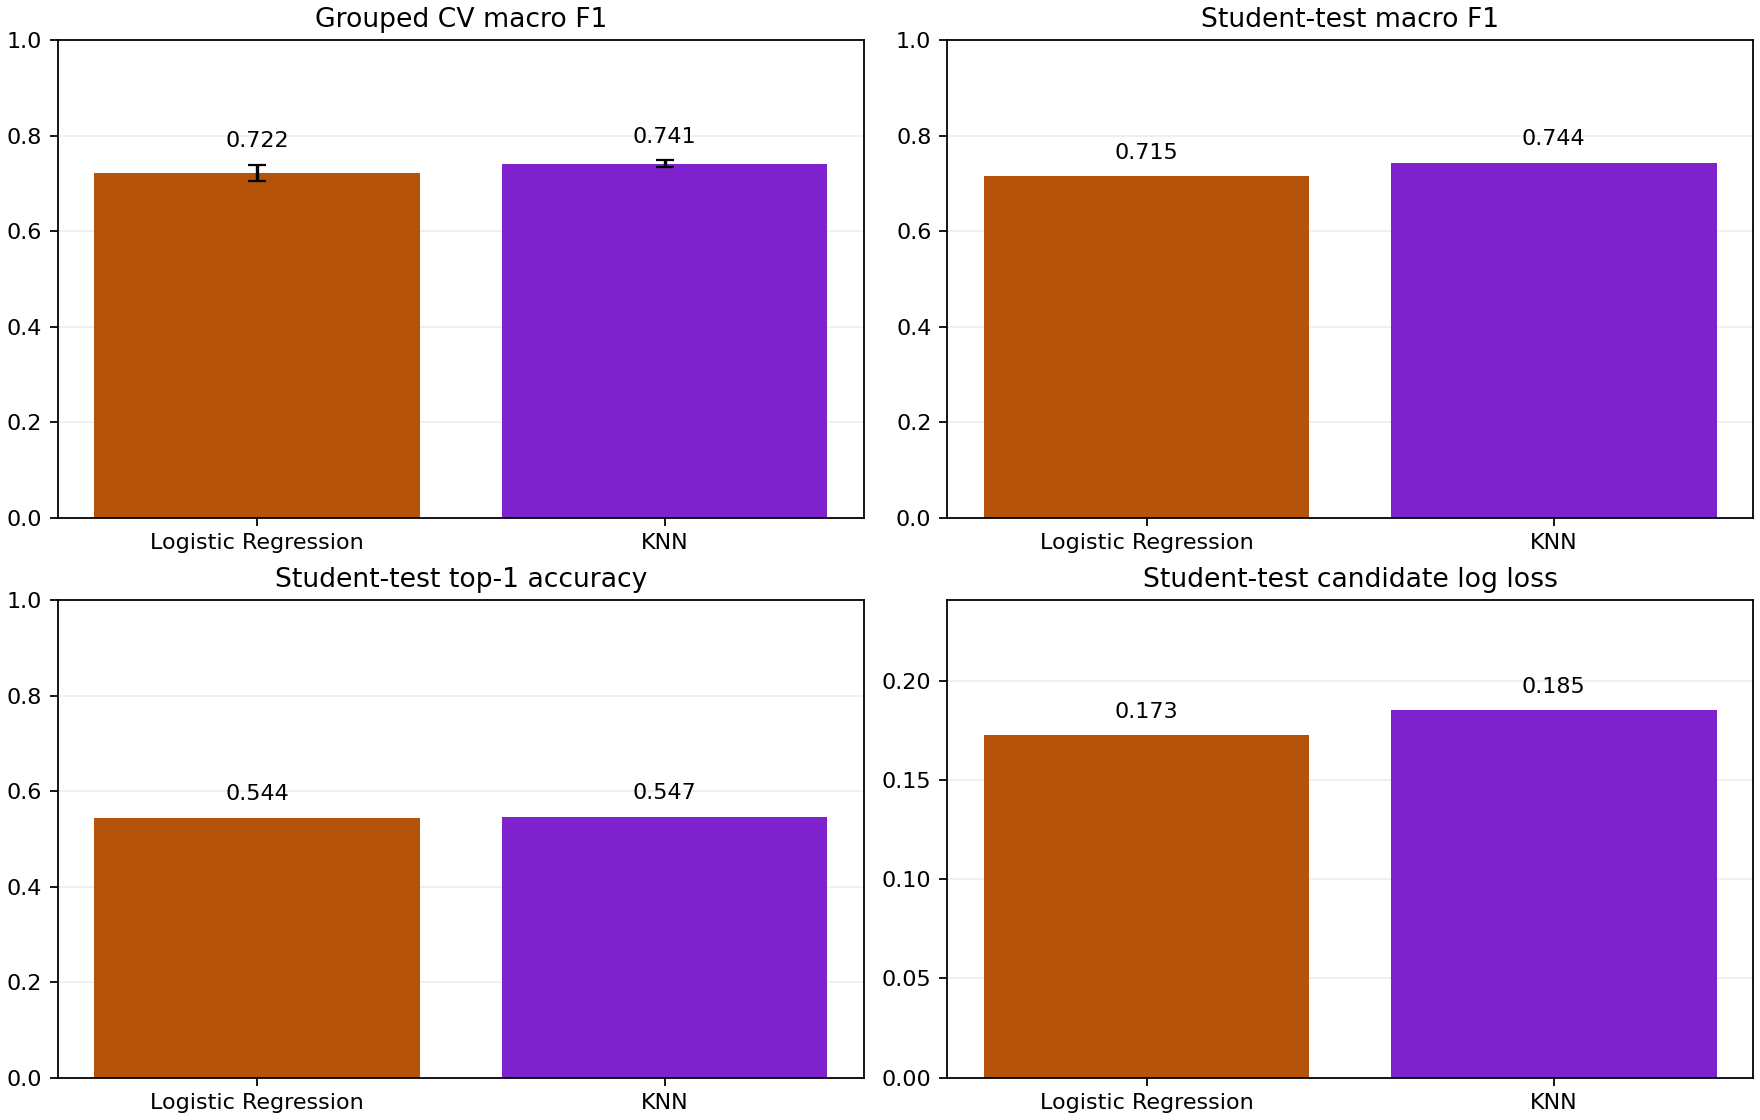

experiments/baselines/student_test_confusion.png


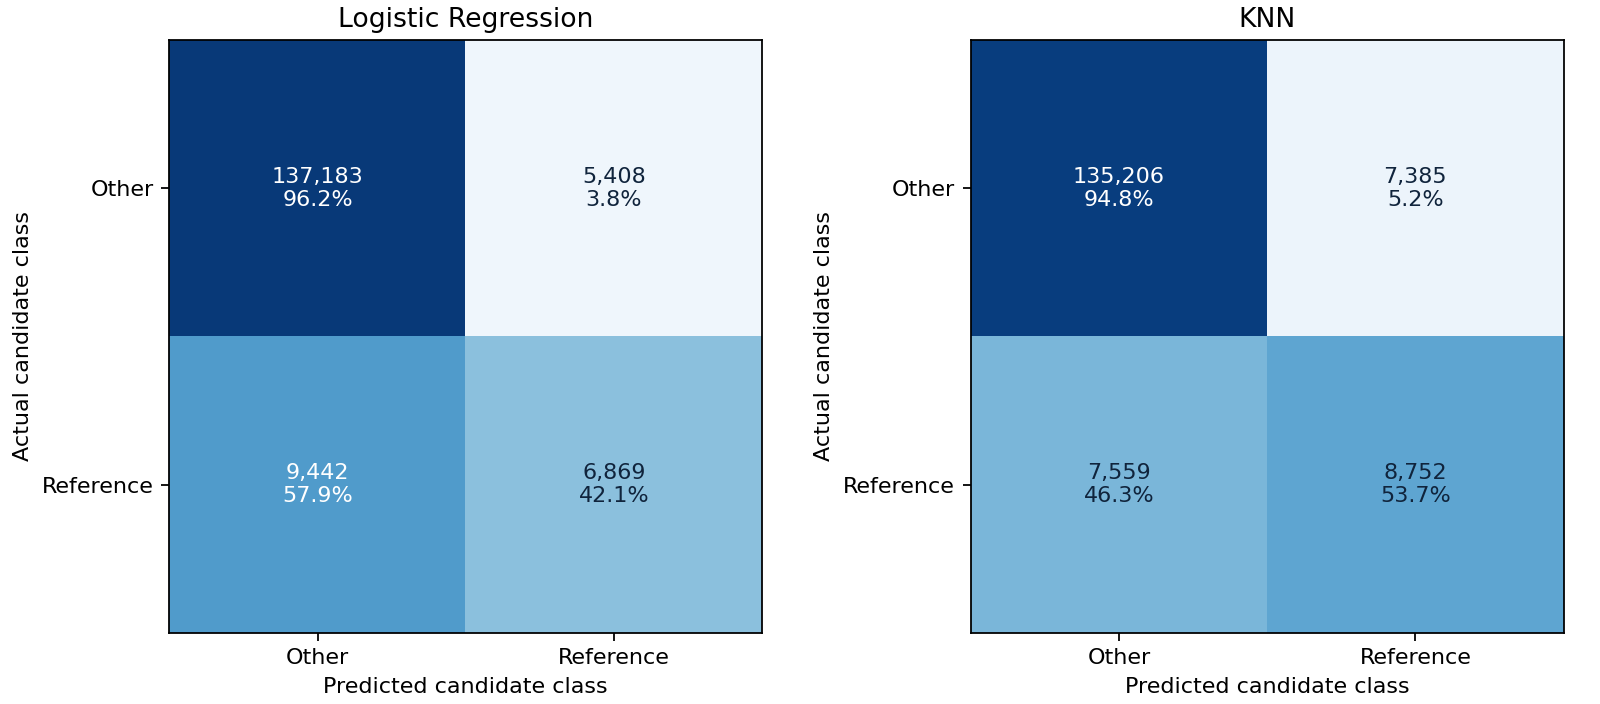

experiments/baselines/student_test_map.png


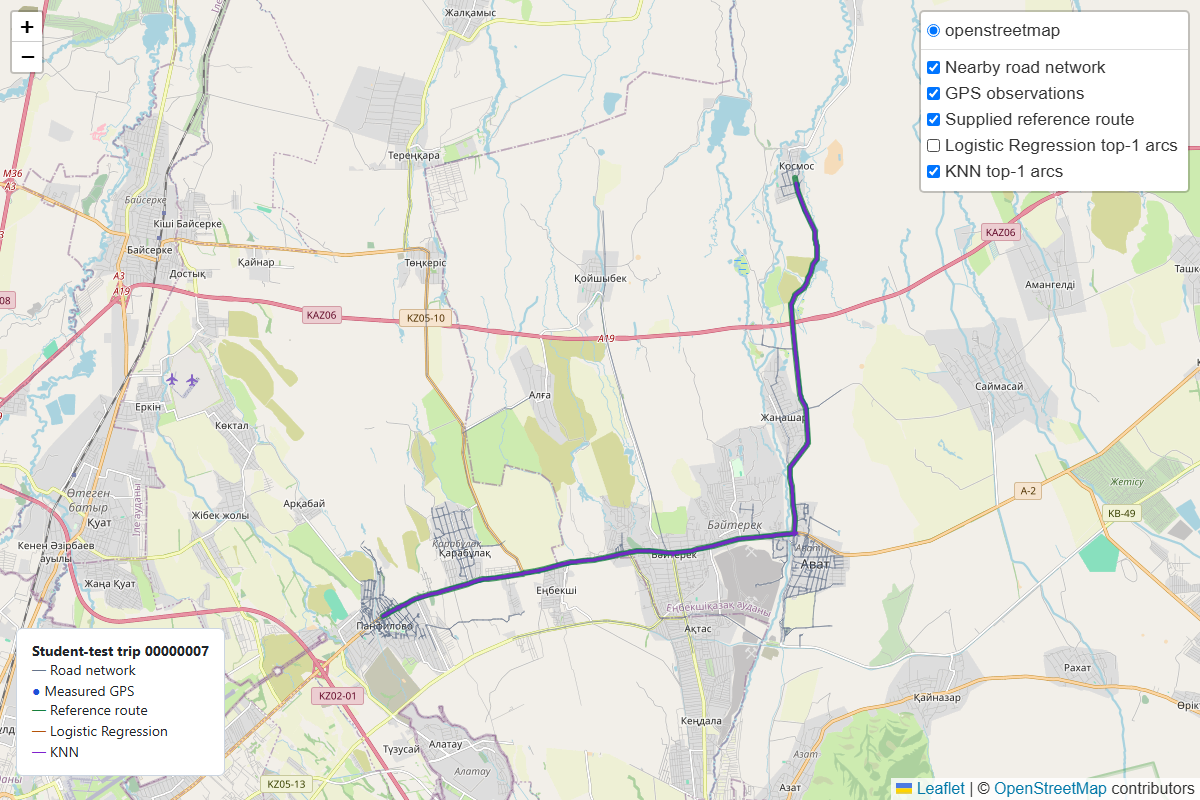

experiments/classifier_tuning/search_objective.png


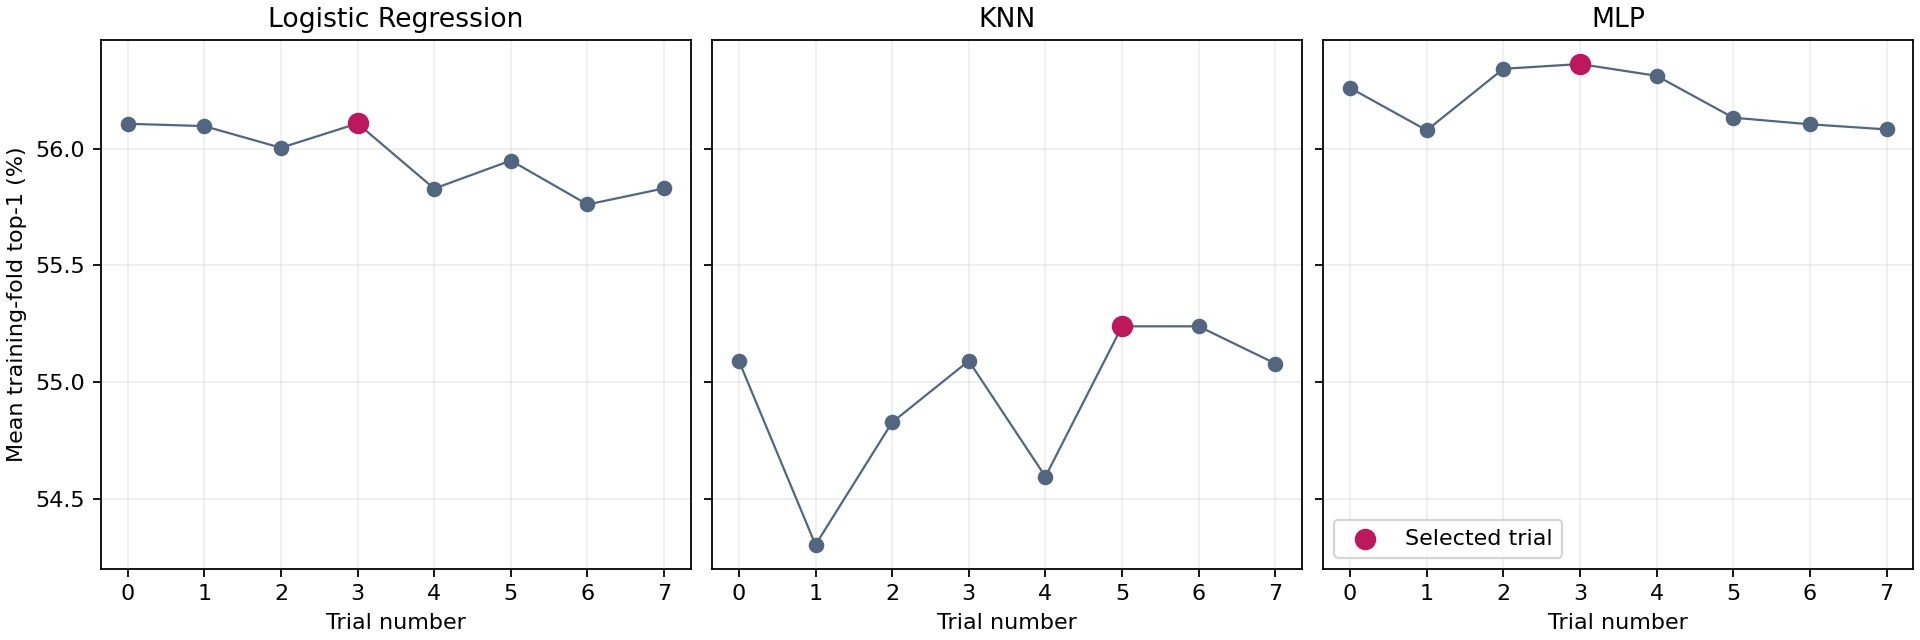

experiments/classifier_tuning/student_test_top1.png


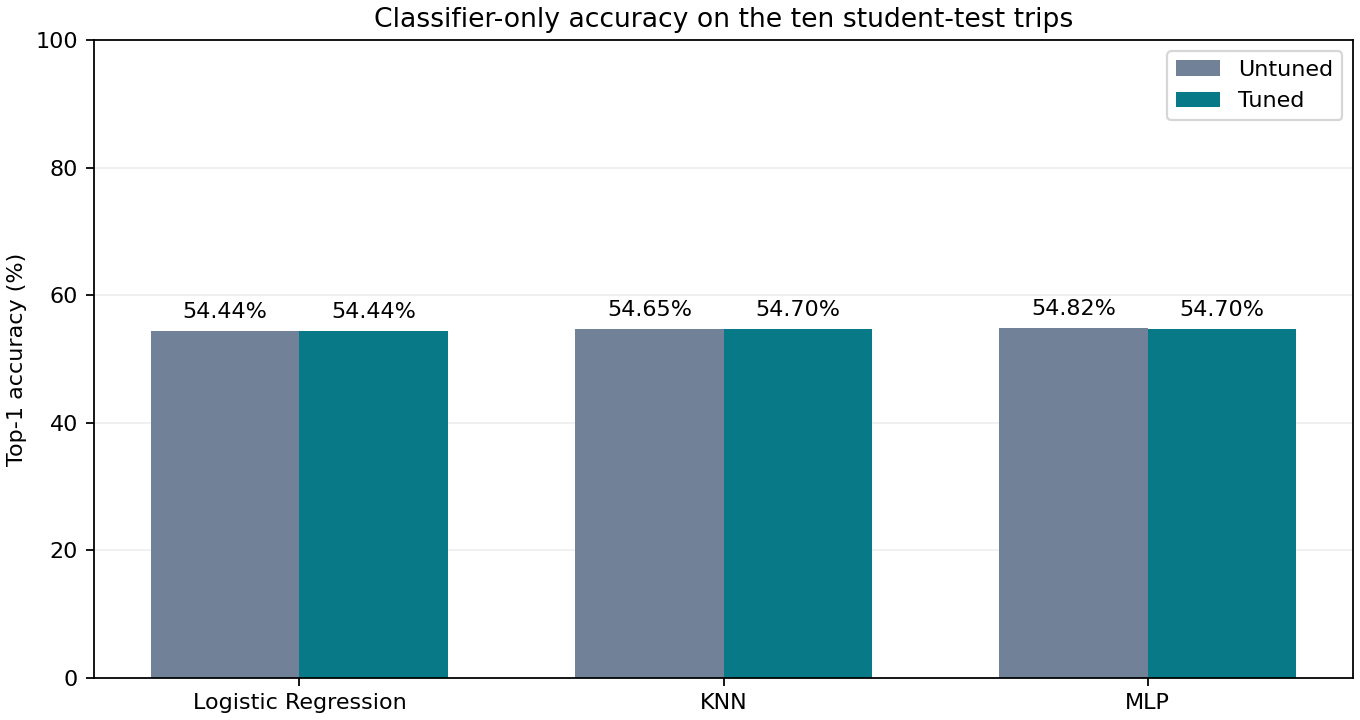

experiments/mlp/comparison.png


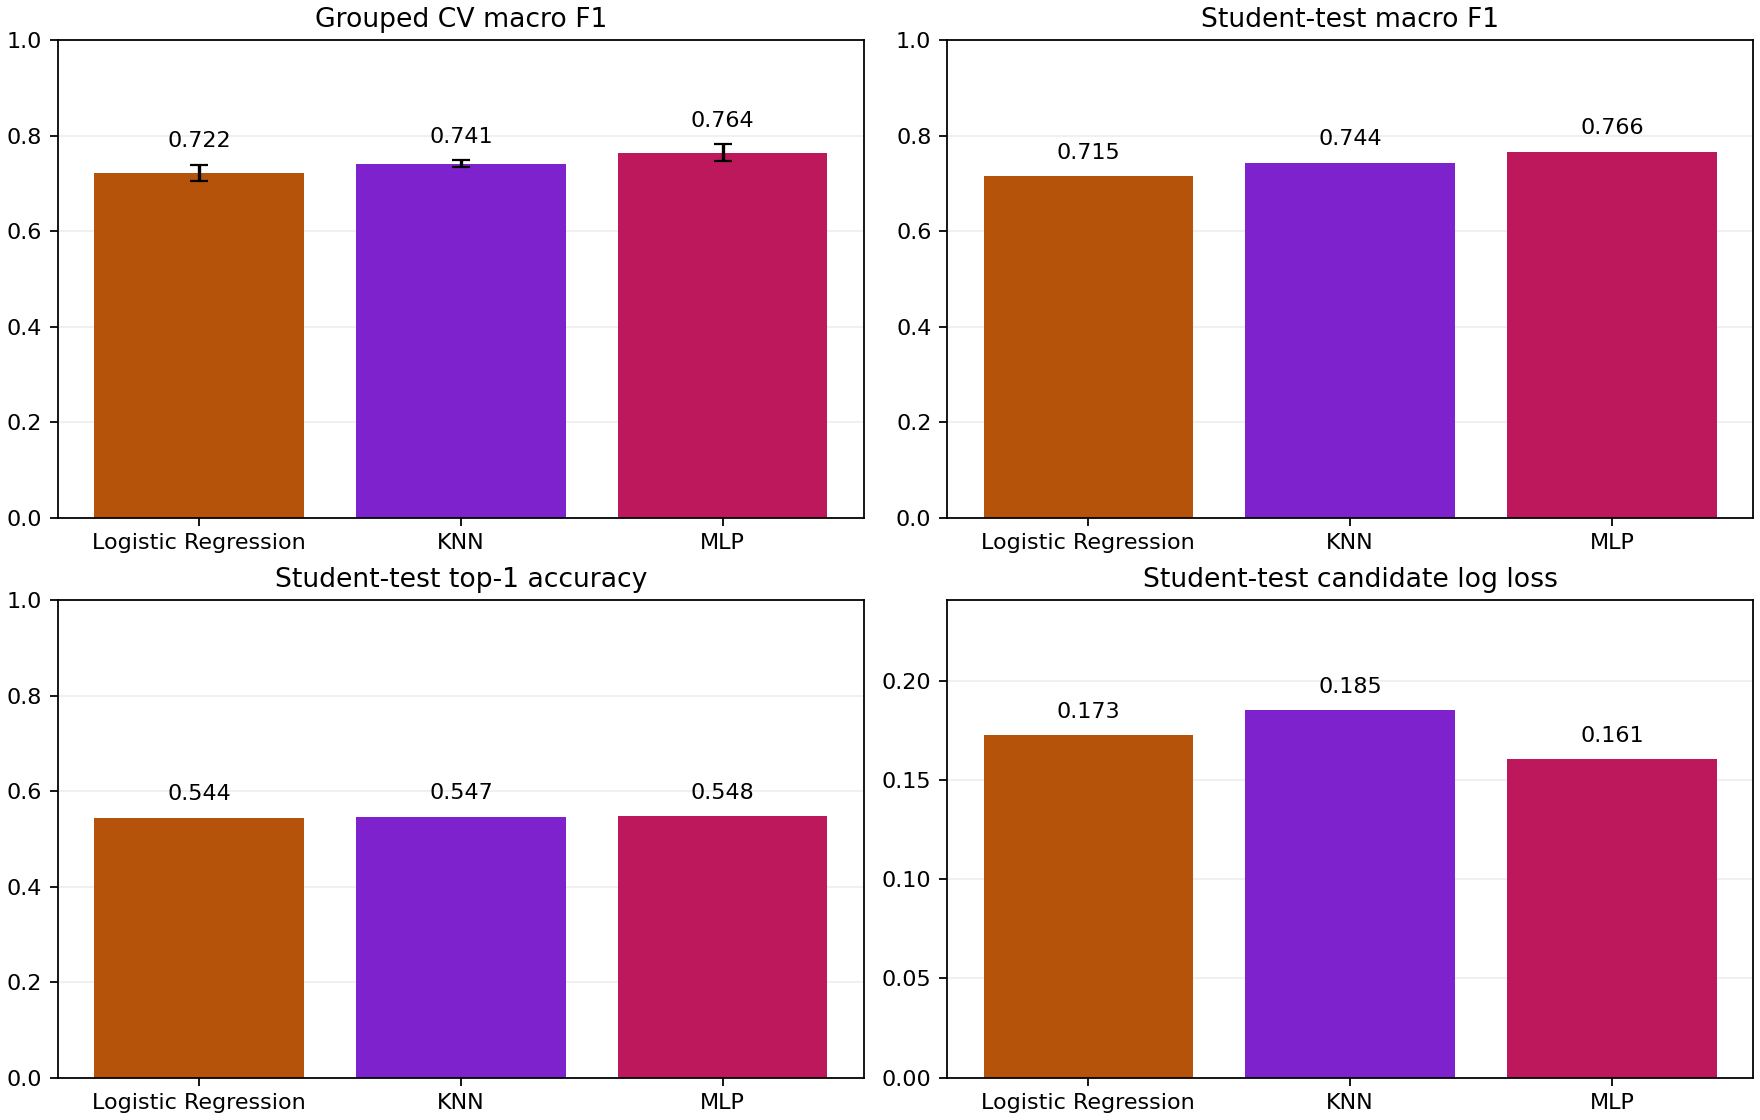

experiments/mlp/learning_curves.png


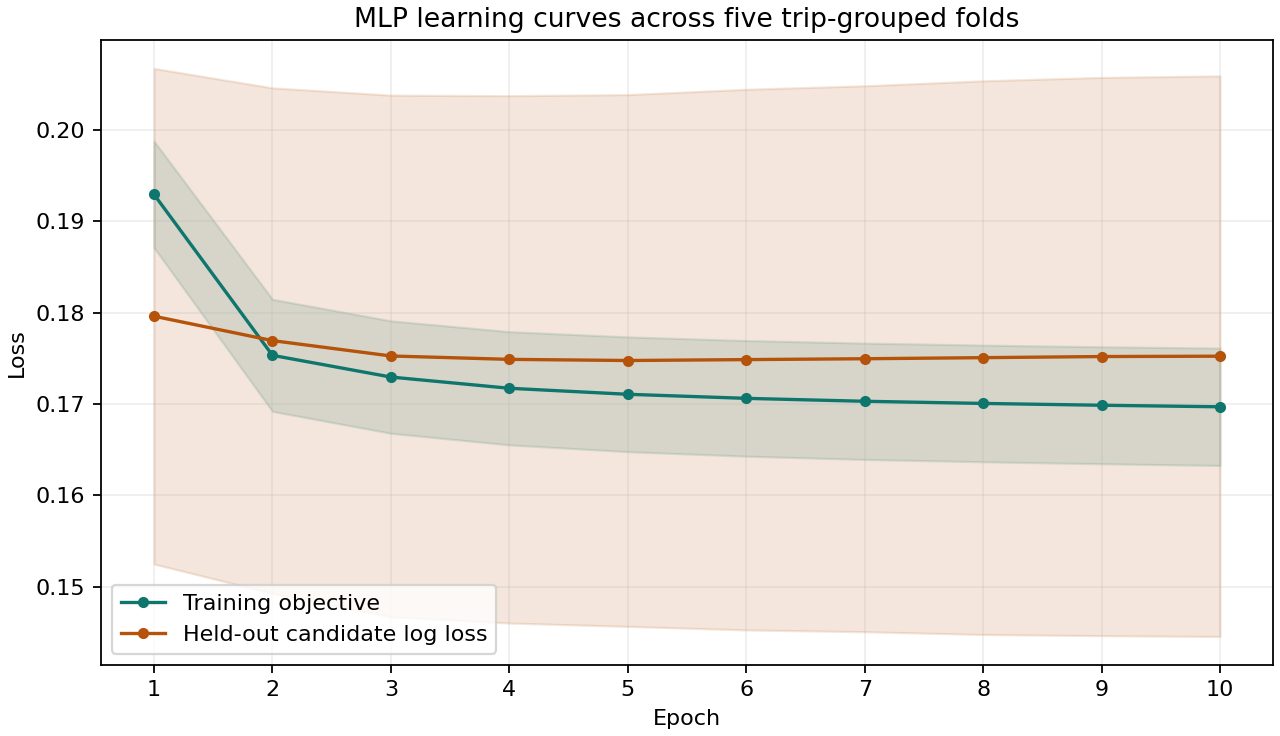

experiments/mlp/student_test_confusion.png


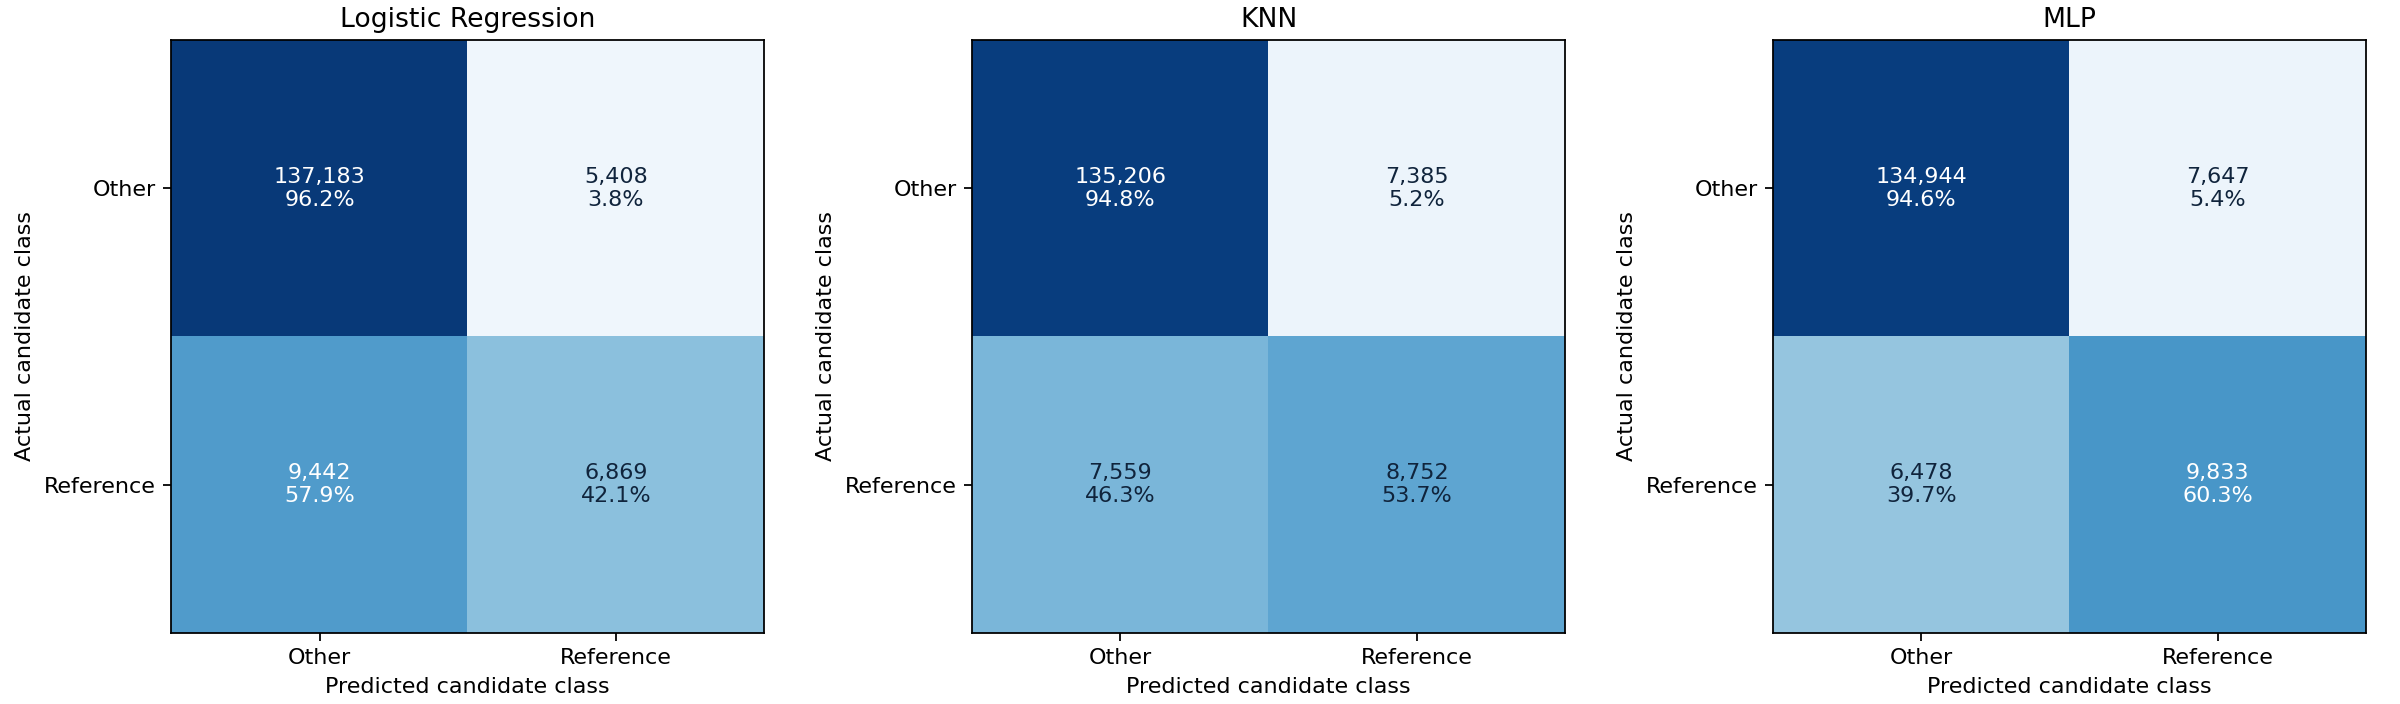

experiments/mlp/student_test_map.png


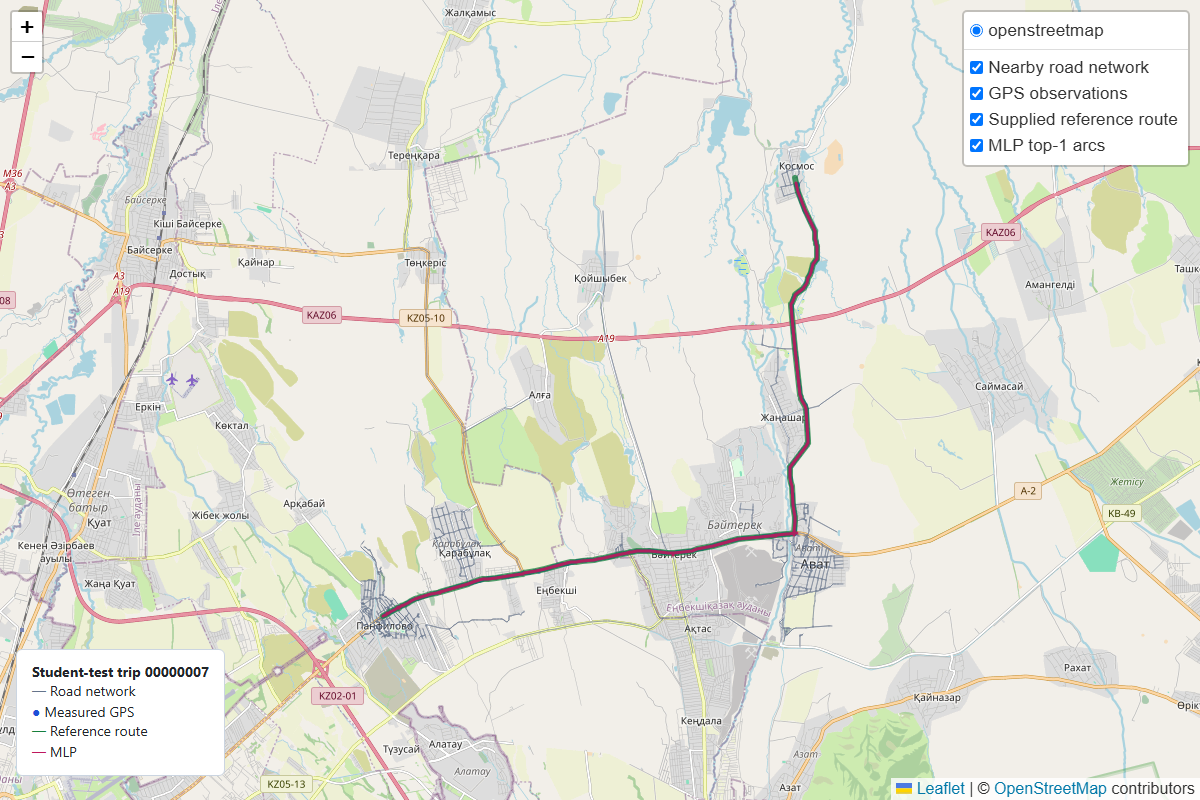

In [25]:
# Display all experiment metric/comparison tables and generated figures.
from IPython.display import Image
for path in sorted(Path('experiments').rglob('*.csv')):
    if any(x in path.name for x in ('metrics','aggregate','comparison','grid','holdout')):
        print(path); display(pd.read_csv(path).head(30))
for path in sorted(Path('experiments').rglob('*.png')):
    print(path); display(Image(filename=str(path),width=900))


In [26]:
# Start the actual FastAPI application and issue live HTTP requests.
import requests
api_log=open(LOGS/'api.log','w')
api_process=subprocess.Popen([sys.executable,'-m','uvicorn','pathsnap.api:app','--host','127.0.0.1','--port','8000'],cwd=REPO,stdout=api_log,stderr=subprocess.STDOUT)
API='http://127.0.0.1:8000'
for attempt in range(60):
    if api_process.poll() is not None: raise RuntimeError((LOGS/'api.log').read_text())
    try:
        response=requests.get(API+'/trips',timeout=2); response.raise_for_status(); break
    except requests.RequestException: time.sleep(1)
else: raise TimeoutError('API startup timed out')
available=response.json(); display(available)
TRIP_ID='00000052'
from html import escape
for model in available['models']:
    response=requests.post(API+'/predict',json={'trip_id':TRIP_ID,'model':model},timeout=600)
    response.raise_for_status(); result=response.json()
    print(model); display(result['evaluation'])
    display(HTML('<iframe style="width:100%;height:650px;border:0" srcdoc="'+escape(result['map_html'],quote=True)+'"></iframe>'))
print('Browser UI is included at ui/index.html. Kaggle localhost is inside the runtime; use these notebook API results for the live demonstration.')


{'trip_ids': ['00000000',
  '00000007',
  '00000009',
  '00000040',
  '00000052',
  '00000056',
  '00000065',
  '00000076',
  '00000077',
  '00000091'],
 'models': {'distance': 'Distance baseline (development)',
  'logistic_regression': 'Logistic Regression (trained)',
  'knn': 'KNN (trained)'}}

distance


{'aligned': 203,
 'ambiguous_excluded': 59,
 'unmatched_excluded': 0,
 'candidate_misses': 0,
 'top1_correct': 164,
 'viterbi_correct': 203,
 'top1_accuracy': 0.8078817733990148,
 'viterbi_accuracy': 1.0}

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


logistic_regression


{'aligned': 203,
 'ambiguous_excluded': 59,
 'unmatched_excluded': 0,
 'candidate_misses': 0,
 'top1_correct': 164,
 'viterbi_correct': 202,
 'top1_accuracy': 0.8078817733990148,
 'viterbi_accuracy': 0.9950738916256158}

knn


{'aligned': 203,
 'ambiguous_excluded': 59,
 'unmatched_excluded': 0,
 'candidate_misses': 0,
 'top1_correct': 168,
 'viterbi_correct': 203,
 'top1_accuracy': 0.8275862068965517,
 'viterbi_accuracy': 1.0}

Browser UI is included at ui/index.html. Kaggle localhost is inside the runtime; use these notebook API results for the live demonstration.


In [27]:
# Package the full run, including models, scores, processed data, maps, UI and logs.
manifest={'revision':REVISION,'completed_commands':completed,'python':sys.version}
Path('/kaggle/working/run_manifest.json').write_text(json.dumps(manifest,indent=2))
subprocess.run([PROJECT_PYTHON,'-m','pip','freeze'],stdout=open('/kaggle/working/installed_packages.txt','w'),check=True)
shutil.make_archive('/kaggle/working/pathsnap_full_run','zip',REPO)
display(FileLink('/kaggle/working/pathsnap_full_run.zip'))
print('Download pathsnap_full_run.zip, pathsnap_logs, run_manifest.json and installed_packages.txt from Kaggle Output.')


Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


/kaggle/working/pathsnap_full_run.zip

Download pathsnap_full_run.zip, pathsnap_logs, run_manifest.json and installed_packages.txt from Kaggle Output.
